In [3]:

import holidays
import seaborn as sns
from statsmodels.graphics.tsaplots import plot_acf
import pandas as pd
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt

In [4]:
def load_and_clean_eco2mix(filepath, start_year=2023, end_year=2026):
    print(f"Chargement du fichier : {filepath}")

    # 1. Chargement avec index_col=False pour empêcher le décalage des colonnes
    try:
        df_raw = pd.read_csv(
            filepath,
            sep="\t",
            encoding="latin1",
            low_memory=False,
            index_col=False
        )
    except Exception as e:
        print(f"Erreur de lecture : {e}")
        return None

    # Nettoyage des noms de colonnes
    df_raw.columns = df_raw.columns.str.strip()

    # Vérification que le décalage est bien réparé
    if 'Date' not in df_raw.columns or 'Heures' not in df_raw.columns:
        print(f"ERREUR : Colonnes introuvables. Colonnes présentes : {df_raw.columns.tolist()}")
        return None

    # 2. Nettoyage strict de la colonne Consommation
    conso_str = df_raw['Consommation'].astype(str).str.strip().str.upper()
    conso_str = conso_str.replace(['ND', '-', 'NAN', ''], np.nan)
    conso_str = conso_str.str.replace(r'\s+', '', regex=True)
    df_raw['conso_mw'] = pd.to_numeric(conso_str, errors="coerce")

    # 3. Création de l'Index Temporel
    dates_str = df_raw['Date'].astype(str).str.strip()
    heures_str = df_raw['Heures'].astype(str).str.strip()

    masque_valide = (dates_str != 'nan') & (heures_str != 'nan')
    df_raw = df_raw[masque_valide].copy()

    df_raw['datetime'] = pd.to_datetime(
        df_raw['Date'].astype(str).str.strip() + ' ' + df_raw['Heures'].astype(str).str.strip(),
        errors="coerce"
    )

    df = df_raw.dropna(subset=['datetime']).copy()

    # 4. Filtrage de la consommation
    df = df.dropna(subset=['conso_mw']).copy()

    if df.empty:
        print("\nERREUR : Le DataFrame est vide après nettoyage.")
        return df

    # 5. Indexation temporelle et filtrage par année
    df = df.sort_values("datetime").set_index("datetime")
    df = df.loc[f"{start_year}-01-01":f"{end_year}-12-31"]

    # 6. Agrégation au pas horaire (1 heure)
    df_hourly = df[["conso_mw"]].resample("1h").mean()

    # 7. Gestion des trous temporels restants
    nb_nans = df_hourly["conso_mw"].isna().sum()
    print(f"-> Nombre d'heures sans aucune donnée : {nb_nans}")
    if nb_nans > 0:
        df_hourly["conso_mw"] = df_hourly["conso_mw"].interpolate(method="time")

    print(f"\n✅ SUCCÈS - Période finale : de {df_hourly.index.min()} à {df_hourly.index.max()}")
    print(f"✅ Nombre total d'heures validées : {len(df_hourly)}")

    return df_hourly


In [5]:
def load_and_clean_synop(filepath):
    """
    Charge un fichier SYNOP, extrait les variables clés (t, ff, n),
    calcule la moyenne nationale et interpole au pas horaire.
    """
    print(f"Traitement météo : {filepath}")

    # Lecture sélective des colonnes (stations, dates, température, vent, nébulosité)
    cols_to_keep = ['name', 'validity_time', 't', 'ff', 'n']
    try:
        df = pd.read_csv(
            filepath,
            sep=';',
            na_values='mq',
            usecols=cols_to_keep,
            low_memory=False
        )
    except Exception as e:
        print(f"Erreur de lecture : {e}")
        return None

# 2. Création de l'index temporel (CORRIGÉE)
    # On affiche la première date brute pour comprendre comment elle est écrite


    # On retire le paramètre "format" pour laisser Pandas s'adapter automatiquement
    df['datetime'] = pd.to_datetime(df['validity_time'].astype(str), errors='coerce')

    nb_echecs = df['datetime'].isna().sum()
    print(f"Lignes supprimées car date illisible : {nb_echecs}")

    df = df.dropna(subset=['datetime'])

    # Conversion des unités : Kelvin vers Celsius
    df['temp_c'] = pd.to_numeric(df['t'], errors='coerce') - 273.15
    df['vent_ms'] = pd.to_numeric(df['ff'], errors='coerce')
    df['nebulosite'] = pd.to_numeric(df['n'], errors='coerce')

    # Agrégation Spatiale : Moyenne de toutes les stations à un instant T
    df_national = df.groupby('datetime')[['temp_c', 'vent_ms', 'nebulosite']].mean()

    # Agrégation Temporelle : Rééchantillonnage de 3h à 1h et interpolation
    df_hourly = df_national.resample('1h').interpolate(method='time')

    return df_hourly

# --- Fusion des archives météo ---
# Adaptez la liste avec les noms de vos fichiers SYNOP téléchargés
fichiers_meteo = ["synop_2023.csv", "synop_2024.csv", "synop_2025.csv", "synop_2026.csv"]
liste_dfs_meteo = [load_and_clean_synop(f) for f in fichiers_meteo]

df_meteo_totale = pd.concat(liste_dfs_meteo).sort_index()
df_meteo_totale = df_meteo_totale[~df_meteo_totale.index.duplicated(keep='first')]

df_meteo_totale.index = df_meteo_totale.index.tz_localize(None)
print(df_meteo_totale.head())


Traitement météo : synop_2023.csv
Lignes supprimées car date illisible : 0
Traitement météo : synop_2024.csv
Lignes supprimées car date illisible : 0
Traitement météo : synop_2025.csv
Lignes supprimées car date illisible : 0
Traitement météo : synop_2026.csv
Lignes supprimées car date illisible : 0
                        temp_c   vent_ms  nebulosite
datetime                                            
2023-01-01 00:00:00  14.527586  4.719298   85.555556
2023-01-01 01:00:00  14.556573  4.541261   85.833333
2023-01-01 02:00:00  14.585559  4.363223   86.111111
2023-01-01 03:00:00  14.614545  4.185185   86.388889
2023-01-01 04:00:00  14.574609  4.010362   87.469136


In [6]:
# 1. Liste de vos fichiers bruts RTE (adaptez les noms selon vos téléchargements)
fichiers_rte = [
    "eCO2mix_RTE_Annuel-Definitif_2023.xls",
    "eCO2mix_RTE_Annuel-Definitif_2024.xls",
    "eCO2mix_RTE_Annuel-Definitif_2025.xls",
    "eCO2mix_RTE_En-cours-Consolide.xls"
]

liste_dfs_conso = []

# 2. Boucle de chargement et de nettoyage (utilisation de la fonction définie plus tôt)
for fichier in fichiers_rte:
    print(f"--- Traitement de {fichier} ---")
    df_annee = load_and_clean_eco2mix(fichier, start_year=2023, end_year=2026)
    if df_annee is not None:
        liste_dfs_conso.append(df_annee)

# 3. Concaténation de l'historique complet
df_conso_total = pd.concat(liste_dfs_conso)

# 4. Tri chronologique et suppression des éventuels doublons aux limites d'années
df_conso_total = df_conso_total.sort_index()
df_conso_total = df_conso_total[~df_conso_total.index.duplicated(keep='first')]

print(f"\nSérie de consommation complète : de {df_conso_total.index.min()} à {df_conso_total.index.max()}")
print(f"Nombre total d'heures : {len(df_conso_total)}")

--- Traitement de eCO2mix_RTE_Annuel-Definitif_2023.xls ---
Chargement du fichier : eCO2mix_RTE_Annuel-Definitif_2023.xls
-> Nombre d'heures sans aucune donnée : 0

✅ SUCCÈS - Période finale : de 2023-01-01 00:00:00 à 2023-12-31 23:00:00
✅ Nombre total d'heures validées : 8760
--- Traitement de eCO2mix_RTE_Annuel-Definitif_2024.xls ---
Chargement du fichier : eCO2mix_RTE_Annuel-Definitif_2024.xls
-> Nombre d'heures sans aucune donnée : 0

✅ SUCCÈS - Période finale : de 2024-01-01 00:00:00 à 2024-12-31 23:00:00
✅ Nombre total d'heures validées : 8784
--- Traitement de eCO2mix_RTE_Annuel-Definitif_2025.xls ---
Chargement du fichier : eCO2mix_RTE_Annuel-Definitif_2025.xls
-> Nombre d'heures sans aucune donnée : 0

✅ SUCCÈS - Période finale : de 2025-01-01 00:00:00 à 2025-12-31 23:00:00
✅ Nombre total d'heures validées : 8760
--- Traitement de eCO2mix_RTE_En-cours-Consolide.xls ---
Chargement du fichier : eCO2mix_RTE_En-cours-Consolide.xls
-> Nombre d'heures sans aucune donnée : 0

✅ SUCCÈ

In [7]:
# Jointure interne sur l'index (les dates/heures
print(df_conso_total.head())
print(df_meteo_totale.head())

df_projet = df_conso_total.join(df_meteo_totale, how='inner')

# Remplissage des éventuels derniers petits trous d'interpolation aux extrémités
df_projet = df_projet.ffill().bfill()

print("Aperçu du DataFrame fusionné :")
print(df_projet.head())

                     conso_mw
datetime                     
2023-01-01 00:00:00   46956.5
2023-01-01 01:00:00   45033.0
2023-01-01 02:00:00   44923.0
2023-01-01 03:00:00   42145.0
2023-01-01 04:00:00   39567.0
                        temp_c   vent_ms  nebulosite
datetime                                            
2023-01-01 00:00:00  14.527586  4.719298   85.555556
2023-01-01 01:00:00  14.556573  4.541261   85.833333
2023-01-01 02:00:00  14.585559  4.363223   86.111111
2023-01-01 03:00:00  14.614545  4.185185   86.388889
2023-01-01 04:00:00  14.574609  4.010362   87.469136
Aperçu du DataFrame fusionné :
                     conso_mw     temp_c   vent_ms  nebulosite
datetime                                                      
2023-01-01 00:00:00   46956.5  14.527586  4.719298   85.555556
2023-01-01 01:00:00   45033.0  14.556573  4.541261   85.833333
2023-01-01 02:00:00   44923.0  14.585559  4.363223   86.111111
2023-01-01 03:00:00   42145.0  14.614545  4.185185   86.388889
2023-01-01

In [8]:
# Exemple pour passer la température (df_meteo) d'un pas de 3h à 1h
# df_meteo_horaire = df_meteo.resample('1h').interpolate(method='time')

In [9]:

jours_feries_fr = holidays.France(years=range(2023, 2027))

# 1. Extraction des composantes temporelles simples
df_projet['heure'] = df_projet.index.hour
df_projet['jour_semaine'] = df_projet.index.dayofweek # 0 = Lundi, 6 = Dimanche
df_projet['mois'] = df_projet.index.month

# 2. Indicateur de week-end (samedi=5, dimanche=6)
df_projet['est_weekend'] = df_projet['jour_semaine'].isin([5, 6]).astype(int)

# 3. Indicateur de jour férié
# On vérifie si la date (sans l'heure) appartient à la liste des jours fériés
df_projet['est_ferie'] = df_projet.index.map(lambda d: int(d.date() in jours_feries_fr))

print("Features calendaires ajoutées :")
print(df_projet[['conso_mw', 'heure', 'jour_semaine', 'est_weekend', 'est_ferie']].head(27))

Features calendaires ajoutées :
                     conso_mw  heure  jour_semaine  est_weekend  est_ferie
datetime                                                                  
2023-01-01 00:00:00   46956.5      0             6            1          1
2023-01-01 01:00:00   45033.0      1             6            1          1
2023-01-01 02:00:00   44923.0      2             6            1          1
2023-01-01 03:00:00   42145.0      3             6            1          1
2023-01-01 04:00:00   39567.0      4             6            1          1
2023-01-01 05:00:00   38240.5      5             6            1          1
2023-01-01 06:00:00   38179.0      6             6            1          1
2023-01-01 07:00:00   38535.0      7             6            1          1
2023-01-01 08:00:00   38958.0      8             6            1          1
2023-01-01 09:00:00   39582.5      9             6            1          1
2023-01-01 10:00:00   41157.5     10             6            1     

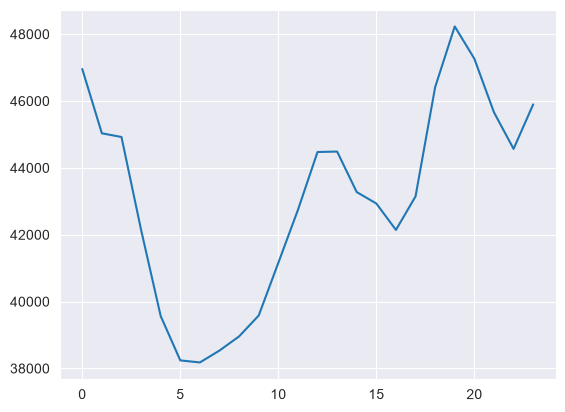

In [10]:
df_24_heures = df_projet[['heure']].head(24)
df_conso = df_projet[['conso_mw']].head(24)

plt.plot( df_24_heures['heure'],df_conso['conso_mw'],)


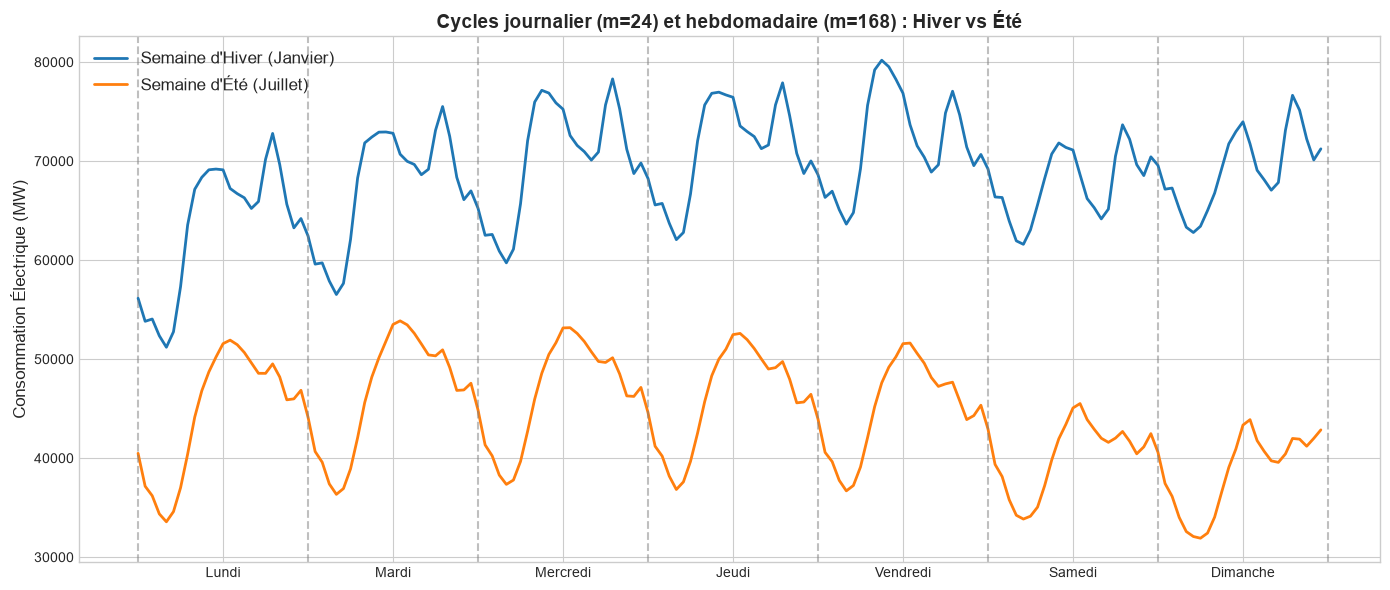

In [11]:



plt.style.use('seaborn-v0_8-whitegrid')

# Sélection de deux semaines de référence en 2023 (commençant un lundi)
semaine_hiver = df_projet.loc['2023-01-16':'2023-01-22']
semaine_ete = df_projet.loc['2023-07-17':'2023-07-23']

fig, ax = plt.subplots(figsize=(14, 6))

# Tracé des deux semaines (on réinitialise l'index temporairement pour les superposer sur les mêmes jours de 0 à 167)
ax.plot(range(len(semaine_hiver)), semaine_hiver['conso_mw'], label='Semaine d\'Hiver (Janvier)', color='#1f77b4', linewidth=2)
ax.plot(range(len(semaine_ete)), semaine_ete['conso_mw'], label='Semaine d\'Été (Juillet)', color='#ff7f0e', linewidth=2)

# Ajout de lignes verticales pour marquer les jours (toutes les 24 heures)
for i in range(0, 169, 24):
    ax.axvline(x=i, color='grey', linestyle='--', alpha=0.5)

ax.set_xticks(range(12, 168, 24))
ax.set_xticklabels(['Lundi', 'Mardi', 'Mercredi', 'Jeudi', 'Vendredi', 'Samedi', 'Dimanche'])
ax.set_title("Cycles journalier (m=24) et hebdomadaire (m=168) : Hiver vs Été", fontsize=14, fontweight='bold')
ax.set_ylabel("Consommation Électrique (MW)", fontsize=12)
ax.legend(fontsize=12)

plt.tight_layout()
plt.show()

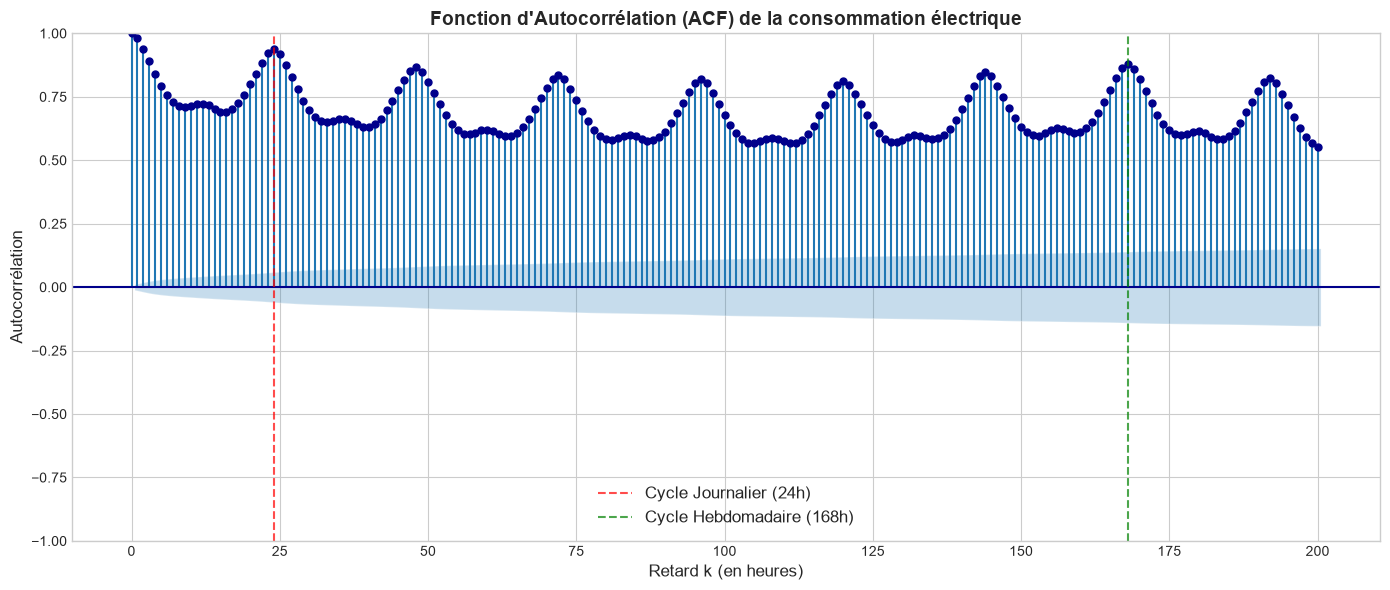

In [12]:
fig, ax = plt.subplots(figsize=(14, 6))

# Calcul de l'ACF sur 200 retards (lags)

plot_acf(df_projet['conso_mw'].dropna(), lags=200, ax=ax, color='darkblue', alpha=0.05)

# Mise en évidence des retards saisonniers clés
ax.axvline(x=24, color='red', linestyle='--', alpha=0.7, label='Cycle Journalier (24h)')
ax.axvline(x=168, color='green', linestyle='--', alpha=0.7, label='Cycle Hebdomadaire (168h)')

ax.set_title("Fonction d'Autocorrélation (ACF) de la consommation électrique", fontsize=14, fontweight='bold')
ax.set_xlabel("Retard k (en heures)", fontsize=12)
ax.set_ylabel("Autocorrélation", fontsize=12)
ax.legend(fontsize=12)

plt.tight_layout()
plt.show()

C:\Users\coren\AppData\Local\Temp\ipykernel_32996\2403701943.py:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_daily, x='type_jour', y='conso_mw', ax=ax2, palette='Set2')


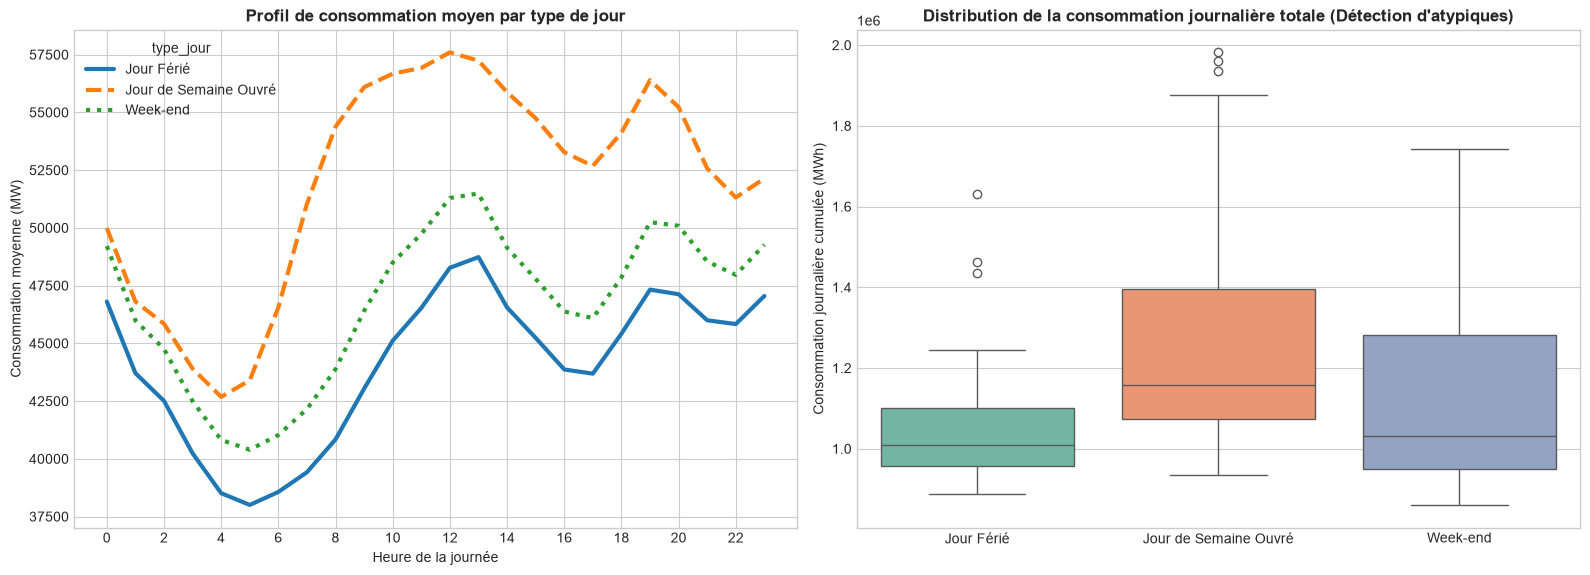

Dates suspectées d'être des 'ponts' (jours ouvrés à consommation anormalement basse) :
[datetime.date(2023, 4, 28) datetime.date(2023, 5, 2)
 datetime.date(2023, 5, 3) datetime.date(2023, 5, 4)
 datetime.date(2023, 5, 5) datetime.date(2023, 5, 9)
 datetime.date(2023, 5, 10) datetime.date(2023, 5, 11)
 datetime.date(2023, 5, 12) datetime.date(2023, 5, 15)
 datetime.date(2023, 5, 16) datetime.date(2023, 5, 17)
 datetime.date(2023, 5, 19) datetime.date(2023, 5, 22)
 datetime.date(2023, 5, 23) datetime.date(2023, 5, 24)
 datetime.date(2023, 5, 25) datetime.date(2023, 5, 26)
 datetime.date(2023, 5, 30) datetime.date(2023, 5, 31)
 datetime.date(2023, 6, 1) datetime.date(2023, 6, 2)
 datetime.date(2023, 6, 5) datetime.date(2023, 6, 6)
 datetime.date(2023, 6, 7) datetime.date(2023, 6, 8)
 datetime.date(2023, 6, 9) datetime.date(2023, 6, 12)
 datetime.date(2023, 6, 13) datetime.date(2023, 6, 14)
 datetime.date(2023, 6, 15) datetime.date(2023, 6, 16)
 datetime.date(2023, 6, 19) datetime.date(202

In [13]:
# 1. Création d'une catégorie "Type de jour" pour faciliter le groupement
def categoriser_jour(row):
    if row['est_ferie'] == 1:
        return 'Jour Férié'
    elif row['est_weekend'] == 1:
        return 'Week-end'
    else:
        return 'Jour de Semaine Ouvré'

df_projet['type_jour'] = df_projet.apply(categoriser_jour, axis=1)

# 2. Calcul du profil horaire moyen pour chaque catégorie
profil_horaire = df_projet.groupby(['heure', 'type_jour'])['conso_mw'].mean().unstack()

# 3. Tracé des profils et détection des valeurs extrêmes
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Graphique de gauche : Les profils horaires moyens
profil_horaire.plot(ax=ax1, linewidth=3, style=['-', '--', ':'])
ax1.set_title("Profil de consommation moyen par type de jour", fontweight='bold')
ax1.set_xlabel("Heure de la journée")
ax1.set_ylabel("Consommation moyenne (MW)")
ax1.set_xticks(range(0, 24, 2))

# Graphique de droite : Distribution pour détecter les valeurs extrêmes (Boîtes à moustaches)
# On calcule l'énergie totale quotidienne pour repérer les jours exceptionnels
df_daily = df_projet.resample('1D').agg({'conso_mw': 'sum', 'type_jour': 'first'})
sns.boxplot(data=df_daily, x='type_jour', y='conso_mw', ax=ax2, palette='Set2')
ax2.set_title("Distribution de la consommation journalière totale (Détection d'atypiques)", fontweight='bold')
ax2.set_ylabel("Consommation journalière cumulée (MWh)")
ax2.set_xlabel("")

plt.tight_layout()
plt.show()

# 4. Identification des valeurs extrêmes (les ponts)
# Exemple : les jours ouvrés qui se comportent comme des jours de week-end (ex: les vendredis de l'Ascension)
ponts_potentiels = df_daily[(df_daily['type_jour'] == 'Jour de Semaine Ouvré') &
                            (df_daily['conso_mw'] < df_daily[df_daily['type_jour'] == 'Week-end']['conso_mw'].mean())]
print("Dates suspectées d'être des 'ponts' (jours ouvrés à consommation anormalement basse) :")
print(ponts_potentiels.index.date[:100]) # Affiche les 10 premières occurrences

premiere étape d'approche avec algo naif etc. on a une MSE qui tourne autour des 5% compte tenu de l'interval mini-max des valeurs de conso :

In [29]:
import pandas as pd
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.linear_model import LinearRegression

# ==========================================
# 1. CRÉATION DES VARIABLES RETARDÉES (LAGS)
# ==========================================
# On crée les colonnes manquantes avant tout découpage
df_projet['conso_lag_48h'] = df_projet['conso_mw'].shift(48)
df_projet['conso_lag_168h'] = df_projet['conso_mw'].shift(168)

# 2. Suppression des valeurs manquantes générées par les retards
# Les 168 premières heures du dataset deviendront NaN, il faut les retirer
df_model = df_projet.dropna().copy()

# ==========================================
# 3. DÉCOUPAGE TEMPOREL STRICT
# ==========================================
train = df_model.loc[:"2024-12-31"]
val   = df_model.loc["2025-01-01":"2025-12-31"]
test  = df_model.loc["2026-01-01":]

y_train = train['conso_mw']
y_test = test['conso_mw']

print(f"Taille du Train : {len(train)} heures | Test : {len(test)} heures\n")

# ==========================================
# 4. CALCUL DES BENCHMARKS SUR LE TEST FINAL
# ==========================================

# BENCHMARK 1 : Persistance Hebdomadaire (J-7)
pred_bench_hebdo = test['conso_lag_168h']
mae_hebdo = mean_absolute_error(y_test, pred_bench_hebdo)
rmse_hebdo = np.sqrt(mean_squared_error(y_test, pred_bench_hebdo))

# BENCHMARK 2 : Persistance "Journalière" (J-1 / retard 48h)
pred_bench_jour = test['conso_lag_48h']
mae_jour = mean_absolute_error(y_test, pred_bench_jour)
rmse_jour = np.sqrt(mean_squared_error(y_test, pred_bench_jour))

# BENCHMARK 3 : Régression Linéaire Simple
features_lin = ['heure', 'jour_semaine', 'est_weekend', 'est_ferie', 'conso_lag_48h', 'conso_lag_168h']
X_train_lin = train[features_lin]
X_test_lin = test[features_lin]

lr = LinearRegression()
lr.fit(X_train_lin, y_train)
pred_lr = lr.predict(X_test_lin)

mae_lr = mean_absolute_error(y_test, pred_lr)
rmse_lr = np.sqrt(mean_squared_error(y_test, pred_lr))

# --- Affichage des résultats ---
print("-" * 50)
print(" RÉSULTATS DES BENCHMARKS SUR LE JEU DE TEST (2026)")
print("-" * 50)
print(f"1. Persistance Journalière (J-1) : MAE = {mae_jour:.0f} MW | RMSE = {rmse_jour:.0f} MW")
print(f"2. Persistance Hebdomadaire (J-7) : MAE = {mae_hebdo:.0f} MW | RMSE = {rmse_hebdo:.0f} MW")
print(f"3. Régression Linéaire Simple    : MAE = {mae_lr:.0f} MW | RMSE = {rmse_lr:.0f} MW")
print("-" * 50)

Taille du Train : 17372 heures | Test : 5832 heures

--------------------------------------------------
 RÉSULTATS DES BENCHMARKS SUR LE JEU DE TEST (2026)
--------------------------------------------------
1. Persistance Journalière (J-1) : MAE = 3858 MW | RMSE = 5063 MW
2. Persistance Hebdomadaire (J-7) : MAE = 3560 MW | RMSE = 4962 MW
3. Régression Linéaire Simple    : MAE = 2539 MW | RMSE = 3374 MW
--------------------------------------------------


                     conso_mw     temp_c   vent_ms  nebulosite  heure  \
datetime                                                                
2023-01-01 00:00:00   46956.5  14.527586  4.719298   85.555556      0   
2023-01-01 01:00:00   45033.0  14.556573  4.541261   85.833333      1   
2023-01-01 02:00:00   44923.0  14.585559  4.363223   86.111111      2   
2023-01-01 03:00:00   42145.0  14.614545  4.185185   86.388889      3   
2023-01-01 04:00:00   39567.0  14.574609  4.010362   87.469136      4   

                     jour_semaine  mois  est_weekend  est_ferie   type_jour  \
datetime                                                                      
2023-01-01 00:00:00             6     1            1          1  Jour Férié   
2023-01-01 01:00:00             6     1            1          1  Jour Férié   
2023-01-01 02:00:00             6     1            1          1  Jour Férié   
2023-01-01 03:00:00             6     1            1          1  Jour Férié   
2023-01-01 04:

C:\Users\coren\PycharmProjects\PythonProject2\.venv\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


[100]	valid_0's rmse: 2733.34	valid_0's l2: 7.47116e+06
[200]	valid_0's rmse: 2585	valid_0's l2: 6.68224e+06
Early stopping, best iteration is:
[238]	valid_0's rmse: 2576.52	valid_0's l2: 6.63845e+06

Performances sur l'échantillon de test :
MAE  : 1958.73 MW
RMSE : 2576.52 MW
MAPE : 4.14 %


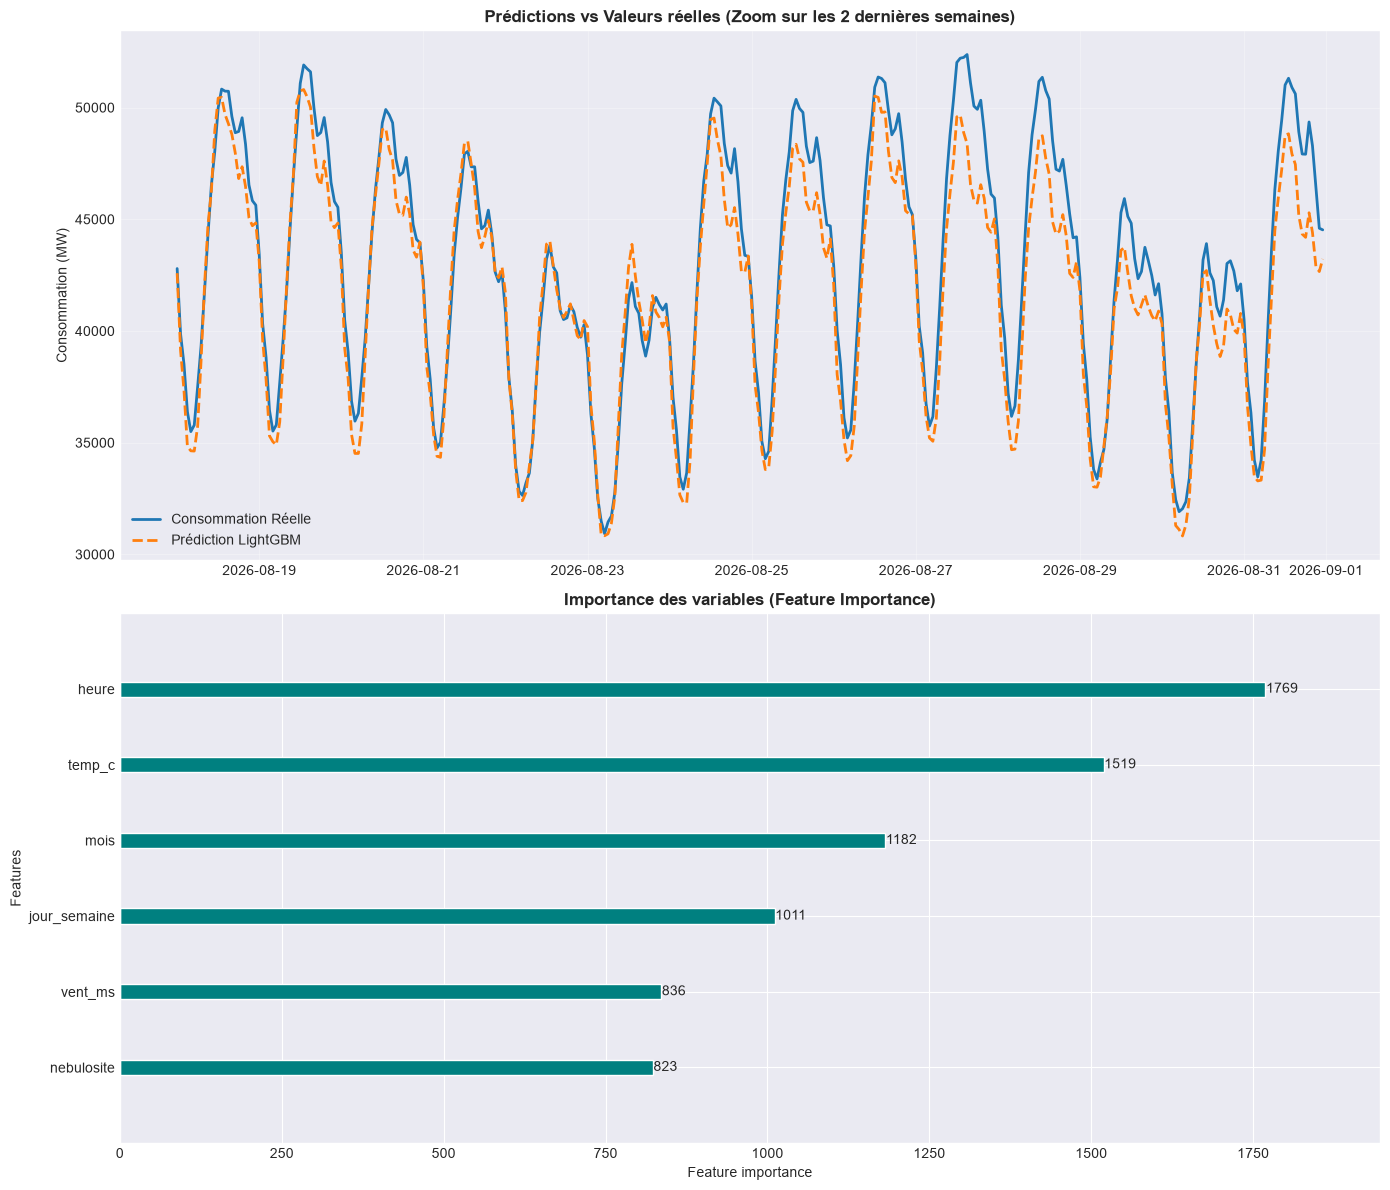

In [36]:
import lightgbm as lgb
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import matplotlib.pyplot as plt

# 1. Sélection des features et de la variable cible
features = [
    'temp_c', 'vent_ms', 'nebulosite',
    'heure', 'jour_semaine', 'mois',
    'est_weekend'
]
target = 'conso_mw'

# Nettoyage de sécurité pour éviter les valeurs manquantes dans les features
df_model = df_projet.dropna(subset=features + [target]).copy()
print(df_model.head())
print(df_model.tail())
X = df_model[features]
y = df_model[target]

# 2. Séparation Train / Test (Split temporel pour les séries chronologiques)
# On réserve les 15 derniers % du jeu de données pour tester le modèle
train_size = int(len(df_model) * 0.85)

X_train, X_test = X.iloc[:train_size], X.iloc[train_size:]
y_train, y_test = y.iloc[:train_size], y.iloc[train_size:]

print(f"Période d'entraînement : de {X_train.index.min()} à {X_train.index.max()}")
print(f"Période de test        : de {X_test.index.min()} à {X_test.index.max()}")

# 3. Initialisation du modèle LightGBM
# Les hyperparamètres peuvent être optimisés ultérieurement (ex: via Optuna ou GridSearchCV)
lgb_model = lgb.LGBMRegressor(
    n_estimators=1000,
    learning_rate=0.05,
    max_depth=8,
    num_leaves=31,
    random_state=42,
    n_jobs=-1
)

# 4. Entraînement avec Early Stopping
# Le modèle s'arrête s'il n'y a pas d'amélioration sur le jeu de test pendant 50 itérations
lgb_model.fit(
    X_train, y_train,
    eval_set=[(X_test, y_test)],
    eval_metric='rmse',
    callbacks=[
        lgb.early_stopping(stopping_rounds=50, verbose=True),
        lgb.log_evaluation(period=100)
    ]
)

# 5. Prédictions
y_pred = lgb_model.predict(X_test)

# 6. Évaluation des performances
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mape = np.mean(np.abs((y_test - y_pred) / y_test)) * 100

print(f"\nPerformances sur l'échantillon de test :")
print(f"MAE  : {mae:.2f} MW")
print(f"RMSE : {rmse:.2f} MW")
print(f"MAPE : {mape:.2f} %")

# 7. Visualisations
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 12))

# Graphique 1 : Comparaison Réel vs Prédiction sur les 2 dernières semaines (336 heures)
ax1.plot(y_test.index[-336:], y_test.iloc[-336:], label='Consommation Réelle', color='#1f77b4', linewidth=2)
ax1.plot(y_test.index[-336:], y_pred[-336:], label='Prédiction LightGBM', color='#ff7f0e', linestyle='--', linewidth=2)
ax1.set_title("Prédictions vs Valeurs réelles (Zoom sur les 2 dernières semaines)", fontweight='bold')
ax1.set_ylabel("Consommation (MW)")
ax1.legend()
ax1.grid(True, alpha=0.3)

# Graphique 2 : Importance des variables
lgb.plot_importance(lgb_model, ax=ax2, max_num_features=10, color='teal', title="Importance des Features (Split)")
ax2.set_title("Importance des variables (Feature Importance)", fontweight='bold')

plt.tight_layout()
plt.show()